# 01 · Modular addition: grokking과 attention 해부

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HisameOgasahara/tmp_llm_dit/blob/main/notebooks/01_modadd.ipynb)

`[a, b, =]`를 보고 `(a + b) mod 113`을 맞히는 태스크입니다. 전체 12,769개 조합 중 **30%만 학습**에 씁니다.

**보게 될 현상: grokking**
1. 학습 데이터는 금방 100% 맞힙니다(외우기). 이때 테스트 정확도는 거의 0입니다.
2. 한참 동안 아무 일도 없는 것처럼 보이다가, 어느 순간 **테스트 정확도가 갑자기 100%로** 뜁니다(일반화).
3. 그 시점에 숫자 임베딩이 **소수의 푸리에 주파수로 정리**됩니다. 모델이 덧셈을 원 위의 회전으로 계산하는 알고리즘을 찾았다는 신호입니다.

**비교하는 것**
| 실행 | 구조 | weight decay | 보려는 것 |
|---|---|---|---|
| GPT-2 | A0 (학습형 위치, LayerNorm, GELU) | 1.0 | 기준 |
| Llama | A1 (RoPE, RMSNorm, SwiGLU) | 1.0 | 구조 차이가 grokking 시점과 해법을 바꾸는가 |
| Llama, wd=0 | A1 | 0 | weight decay 없이도 일반화되는가 (ablation) |

1층, d_model 128, head 4개. T4 기준 실행당 수 분입니다.

## 0. 환경 준비

In [1]:
import os
REPO_DIR = "/content/tmp_llm_dit"
if not os.path.exists(REPO_DIR):
    !git clone -q https://github.com/HisameOgasahara/tmp_llm_dit.git {REPO_DIR}
else:
    !git -C {REPO_DIR} pull -q
%cd {REPO_DIR}
!pip -q install -U -r requirements-colab.txt
# Colab 기본 torchao 가 최신 diffusers 와 버전이 안 맞아 import 가 깨짐 → 쓰지 않으므로 제거
!pip -q uninstall -y torchao

/content/tmp_llm_dit
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 106.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 132.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 123.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 127.7 MB/s eta 0:00:00


In [2]:
import sys, torch
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음 (런타임 유형을 GPU로 바꾸세요)")
!git log -1 --format='repo commit: %h %s'

torch 2.11.0+cu130 | GPU: Tesla T4
repo commit: 5036797 Colab을 통해 생성됨


## 1. 설정과 데이터

In [3]:
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 그래프 한글 폰트
import torch
from miniarch.train import seed_all, get_device, count_params
from miniarch.tasks import modadd
from miniarch.analysis.fourier import freq_energy
from miniarch.analysis.attention import capture_attention, plot_heads

PREFIX = "01_modadd"
dev = get_device()
P, FRAC, STEPS = 113, 0.3, 30000      # 빨리 훑어보려면 STEPS 를 줄이세요 (grokking 은 보통 1~2만 step 근처)
D_MODEL, N_HEAD, N_LAYER = 128, 4, 1

data = modadd.make_data(P, FRAC, seed=0, device=dev)
print(f"학습 {len(data.train_y):,}개 / 테스트 {len(data.test_y):,}개")
print("예시 입력:", data.train_x[:3].tolist(), "→ 정답", data.train_y[:3].tolist(), f"(토큰 {P} = '=')")

학습 3,830개 / 테스트 8,939개
예시 입력: [[37, 1, 113], [23, 9, 113], [2, 43, 113]] → 정답 [38, 32, 45] (토큰 113 = '=')


## 2. 학습

세 실행을 차례로 돌립니다. 진행 표시줄의 `train`/`test`는 정확도, `wn`은 전체 가중치 크기입니다.

In [4]:
RUNS = {
    "GPT-2":       dict(kind="gpt2",  wd=1.0),
    "Llama":       dict(kind="llama", wd=1.0),
    "Llama, wd=0": dict(kind="llama", wd=0.0),
}
models, hists = {}, {}
for name, cfg in RUNS.items():
    seed_all(0)
    m = modadd.build_model(cfg["kind"], P, D_MODEL, N_HEAD, N_LAYER).to(dev)
    print(f"\n▶ {name}  params={count_params(m):,}")
    hists[name] = modadd.train(m, data, steps=STEPS, wd=cfg["wd"])
    models[name] = m
    h = hists[name]
    print(f"  외우기 완료(train>99%): step {h['memorize_step']}  |  일반화(test>99%): step {h['grok_step']}")


▶ GPT-2  params=213,504


  0%|          | 0/30001 [00:00<?, ?it/s]

  외우기 완료(train>99%): step 100  |  일반화(test>99%): step 600

▶ Llama  params=277,120


  0%|          | 0/30001 [00:00<?, ?it/s]

  외우기 완료(train>99%): step 100  |  일반화(test>99%): step 600

▶ Llama, wd=0  params=277,120


  0%|          | 0/30001 [00:00<?, ?it/s]

  외우기 완료(train>99%): step 100  |  일반화(test>99%): step 2200


## 3. 학습 곡선

- **왼쪽**: 점선이 학습, 실선이 테스트 정확도입니다. 두 선 사이의 간격이 "외웠지만 아직 이해 못 한" 구간입니다.
- **가운데**: weight decay가 있으면 외운 뒤 가중치가 점점 작아지고, 그 끝에서 일반화가 일어납니다. 외우는 해법보다 일반화 해법이 가중치가 작아서 weight decay가 그쪽으로 밀어줍니다.
- **오른쪽**: 임베딩 에너지 중 상위 5개 주파수가 차지하는 비율입니다. grokking 시점에 급격히 올라가면 푸리에 해법을 찾은 것입니다.

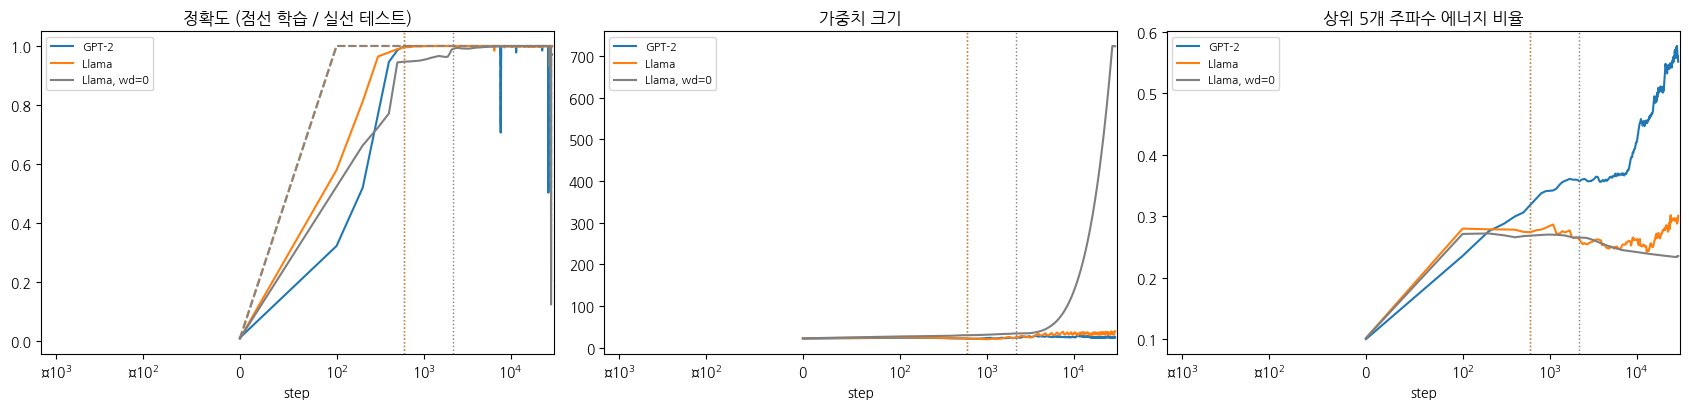

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
colors = dict(zip(RUNS, ["tab:blue", "tab:orange", "tab:gray"]))
for name, h in hists.items():
    c = colors[name]
    axes[0].plot(h["step"], h["train_acc"], "--", color=c, alpha=0.7)
    axes[0].plot(h["step"], h["test_acc"], "-", color=c, label=name)
    axes[1].plot(h["step"], h["weight_norm"], color=c, label=name)
    axes[2].plot(h["step"], h["fourier_top5"], color=c, label=name)
    if h["grok_step"]:
        for ax in axes:
            ax.axvline(h["grok_step"], color=c, ls=":", lw=1)
for ax, t in zip(axes, ["정확도 (점선 학습 / 실선 테스트)", "가중치 크기", "상위 5개 주파수 에너지 비율"]):
    ax.set_xscale("symlog", linthresh=100); ax.set_title(t); ax.set_xlabel("step"); ax.legend(fontsize=8)
fig.tight_layout(); fig_curves = fig

## 4. 임베딩의 푸리에 스펙트럼

숫자 0~112의 임베딩을 주파수별로 분해한 결과입니다.
- grokking 한 모델은 **몇 개의 주파수에만 뾰족한 막대**가 섭니다. 모델이 고른 "핵심 주파수"입니다.
- 일반화하지 못한 모델은 에너지가 고르게 퍼져 있습니다.
- GPT-2와 Llama가 **같은 주파수를 골랐는지**도 보세요. 보통 시드와 구조에 따라 다른 주파수를 고릅니다.

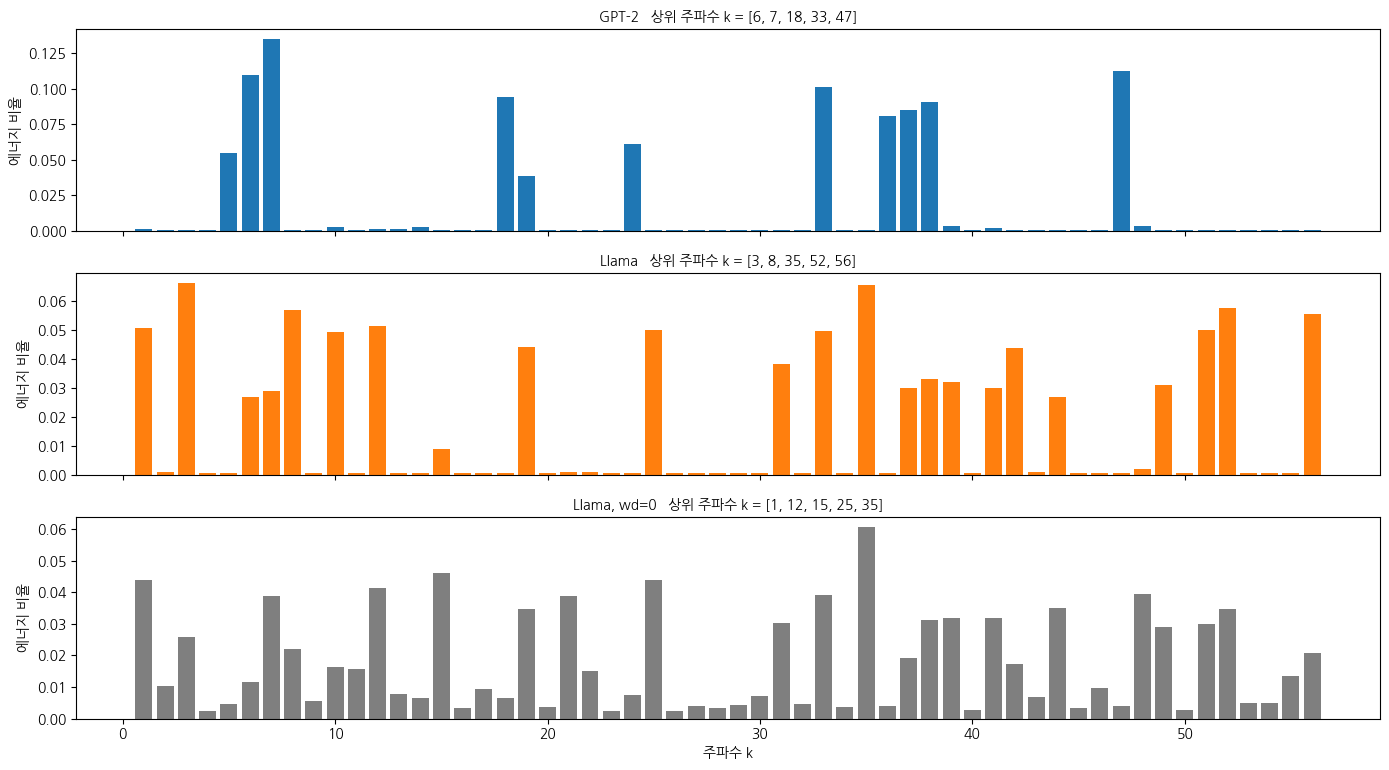

In [6]:
fig, axes = plt.subplots(len(models), 1, figsize=(14, 2.6 * len(models)), sharex=True)
for ax, (name, m) in zip(axes, models.items()):
    e = freq_energy(modadd.embedding_weight(m).detach(), P).cpu()
    e = e / e.sum()
    ax.bar(range(1, len(e) + 1), e, color=colors[name])
    top = e.topk(5).indices + 1
    ax.set_title(f"{name}   상위 주파수 k = {sorted(top.tolist())}", fontsize=10)
    ax.set_ylabel("에너지 비율")
axes[-1].set_xlabel("주파수 k")
fig.tight_layout(); fig_fourier = fig

## 5. Attention map

테스트 입력 전체에 대해 평균낸 attention입니다. 각 칸은 "행 토큰이 열 토큰을 얼마나 보는가"입니다.
- 정답은 마지막 `=` 위치에서 나오므로 **맨 아래 행**이 핵심입니다. `=`가 `a`와 `b`를 어떻게 나눠 보는지 확인하세요.
- causal 구조라 대각선 위쪽은 항상 0입니다.
- GPT-2(학습형 위치)와 Llama(RoPE)가 head를 다르게 쓰는지 비교해 보세요.

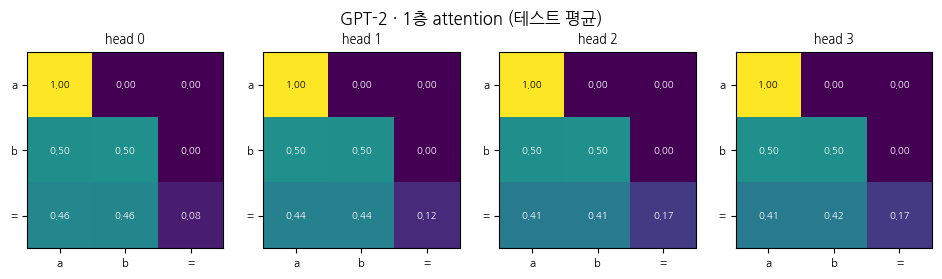

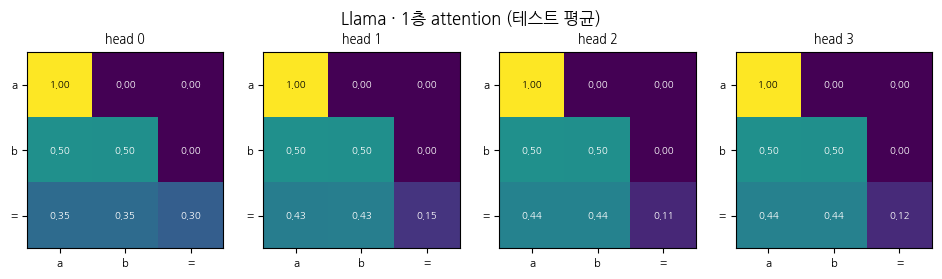

In [7]:
labels = ["a", "b", "="]
attn_figs = {}
for name, m in models.items():
    if "wd=0" in name:
        continue
    m.eval()
    att = capture_attention(m, lambda m=m: m(data.test_x))
    P_mean = next(iter(att.values())).mean(0)           # [H, 3, 3]
    attn_figs[name] = plot_heads(P_mean, labels, labels, title=f"{name} · 1층 attention (테스트 평균)")
    plt.show()

## 6. 결과 저장

- `results/`에 곡선 수치(json)와 그림(png)이 저장됩니다.
- 출력이 담긴 노트북을 기록으로 남기려면 **파일 → GitHub에 사본 저장**을 쓰세요.

In [8]:
import datetime, json, shutil
STAMP = datetime.datetime.now().strftime("%Y%m%d-%H%M")
os.makedirs("results", exist_ok=True)

def save_fig(fig, name):
    path = f"results/{PREFIX}_{name}_{STAMP}.png"
    fig.savefig(path, dpi=120, bbox_inches="tight")
    return path

summary = {n: {"memorize_step": h["memorize_step"], "grok_step": h["grok_step"],
               "final_test_acc": h["test_acc"][-1]} for n, h in hists.items()}
with open(f"results/{PREFIX}_{STAMP}.json", "w") as f:
    json.dump({"config": dict(P=P, FRAC=FRAC, STEPS=STEPS, D_MODEL=D_MODEL, N_HEAD=N_HEAD, N_LAYER=N_LAYER),
               "summary": summary, "history": hists}, f)
save_fig(fig_curves, "curves"); save_fig(fig_fourier, "fourier")
for n, f in attn_figs.items():
    save_fig(f, "attn_" + n.replace(" ", "").replace(",", "_"))
print(json.dumps(summary, indent=1, ensure_ascii=False))
print([f for f in os.listdir("results") if STAMP in f])

SAVE_TO_DRIVE = False   # True 로 바꾸면 results/ 를 Drive 에도 복사 (체크포인트 포함)
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    dst = "/content/drive/MyDrive/tmp_llm_dit/results"
    os.makedirs(dst, exist_ok=True)
    for f in os.listdir("results"):
        if STAMP in f:
            shutil.copy(f"results/{f}", dst)
    print("drive:", dst)

{
 "GPT-2": {
  "memorize_step": 100,
  "grok_step": 600,
  "final_test_acc": 1.0
 },
 "Llama": {
  "memorize_step": 100,
  "grok_step": 600,
  "final_test_acc": 0.9978744983673096
 },
 "Llama, wd=0": {
  "memorize_step": 100,
  "grok_step": 2200,
  "final_test_acc": 0.9721445441246033
 }
}
['01_modadd_20261014-0642.json', '01_modadd_attn_Llama_20261014-0642.png', '01_modadd_fourier_20261014-0642.png', '01_modadd_curves_20261014-0642.png', '01_modadd_attn_GPT-2_20261014-0642.png']
